<a href="https://colab.research.google.com/github/akshdat29/PhDAI-733-B01/blob/main/Heart_Disease_Preprocessing_and_Initial_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Heart Disease Prediction: Data Preprocessing and Initial Model
**Dataset:** Heart Disease UCI (Cleveland subset, 303 patients)
**Stakeholder question:** Can routine clinical measurements flag patients who are likely to have heart disease, so clinicians can prioritise follow-up tests?
**Target:** `num` (0 = no disease, 1–4 = disease). We convert it to a binary label: `1` = disease present.
**Team members:** _(add names)_

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load the data
The UCI file has no header and uses `?` for missing values. We try the UCI URL first. If that fails, we fall back to a local file (in Colab, upload `processed.cleveland.data`).

In [ ]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
COLS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
        "exang", "oldpeak", "slope", "ca", "thal", "num"]

try:
    df = pd.read_csv(URL, names=COLS, na_values="?")
    print("Loaded from UCI")
except Exception as e:
    print("UCI download failed:", e)
    try:
        from google.colab import files
        files.upload()  # choose processed.cleveland.data
    except ImportError:
        pass  # not in Colab: expect the file in the working directory
    df = pd.read_csv("processed.cleveland.data", names=COLS, na_values="?")

print(df.shape)
df.head()

Loaded from UCI
(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Exploratory data analysis
We check size, types, missing values, duplicates, and class balance before changing anything.

In [ ]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num      

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


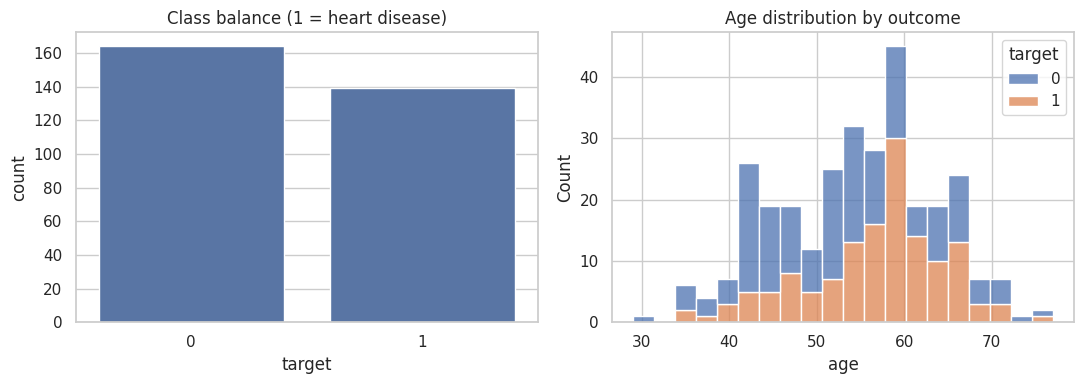

target
0    0.541
1    0.459
Name: proportion, dtype: float64


In [ ]:
df["target"] = (df["num"] > 0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="target", ax=axes[0])
axes[0].set_title("Class balance (1 = heart disease)")
sns.histplot(data=df, x="age", hue="target", multiple="stack", bins=20, ax=axes[1])
axes[1].set_title("Age distribution by outcome")
plt.tight_layout(); plt.show()

print(df["target"].value_counts(normalize=True).round(3))

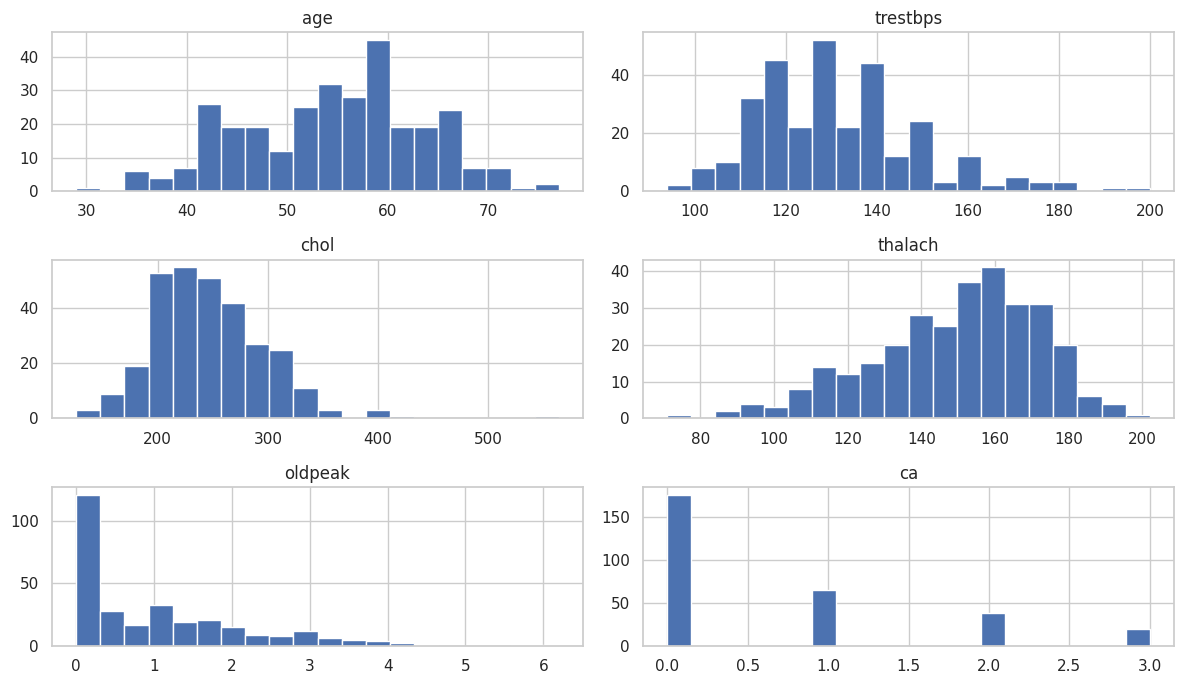

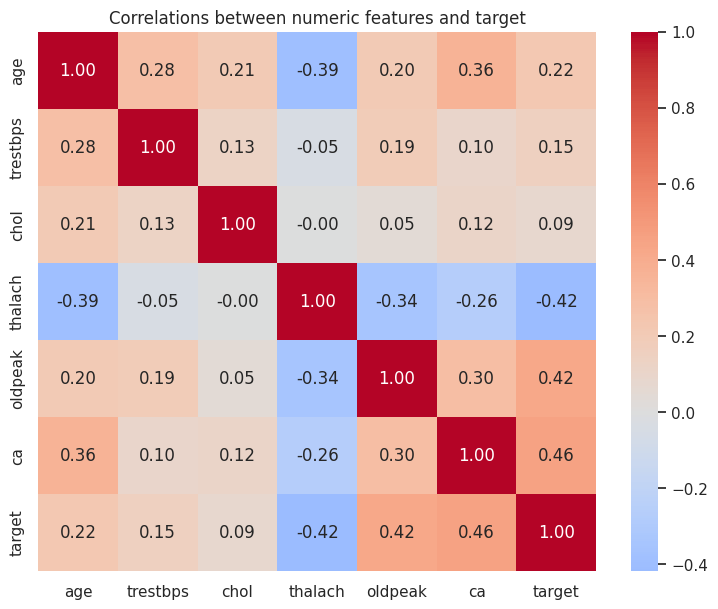

In [ ]:
numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
df[numeric_cols].hist(figsize=(12, 7), bins=20)
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(df[numeric_cols + ["target"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlations between numeric features and target")
plt.show()

## 3. Cleaning and preprocessing
- Remove exact duplicate rows.
- Missing values (`ca`, `thal`) are imputed **inside the modelling pipeline, after the train/test split**. Imputing or scaling on the full dataset first would leak test-set information into training.
- `cp`, `restecg`, `slope`, `thal` are category codes, so they are one-hot encoded. `sex`, `fbs`, `exang` are binary and are encoded the same way.

In [ ]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dropped {before - len(df)} duplicate rows; {len(df)} remain")

X = df.drop(columns=["num", "target"])
y = df["target"]

num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Dropped 0 duplicate rows; 303 remain
Train: (227, 13)  Test: (76, 13)


In [ ]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])

## 4. Initial model development
We compare two baselines with 5-fold stratified cross-validation on the training set. ROC AUC is the main metric because it does not depend on a single decision threshold.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

results = {}
for name, clf in models.items():
    pipe = Pipeline([("pre", preprocessor), ("clf", clf)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    results[name] = scores
    print(f"{name:20s} ROC AUC = {scores.mean():.3f} ± {scores.std():.3f}")

Logistic Regression  ROC AUC = 0.899 ± 0.043
Random Forest        ROC AUC = 0.897 ± 0.039


## 5. Hyperparameter tuning
A small grid search on the Random Forest. Parameters are prefixed with `clf__` because they belong to the pipeline step named `clf`.

In [ ]:
rf_pipe = Pipeline([("pre", preprocessor),
                    ("clf", RandomForestClassifier(random_state=RANDOM_STATE))])

param_grid = {
    "clf__n_estimators": [100, 300],
    "clf__max_depth": [3, 5, None],
    "clf__min_samples_leaf": [1, 3],
}
grid = GridSearchCV(rf_pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print(f"Best CV ROC AUC: {grid.best_score_:.3f}")
best_model = grid.best_estimator_

Best parameters: {'clf__max_depth': None, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 300}
Best CV ROC AUC: 0.907


## 6. Evaluation on the held-out test set
The test set is used once, for the final model only.

              precision    recall  f1-score   support

  No disease       0.89      0.83      0.86        41
     Disease       0.82      0.89      0.85        35

    accuracy                           0.86        76
   macro avg       0.86      0.86      0.86        76
weighted avg       0.86      0.86      0.86        76

Test ROC AUC: 0.936


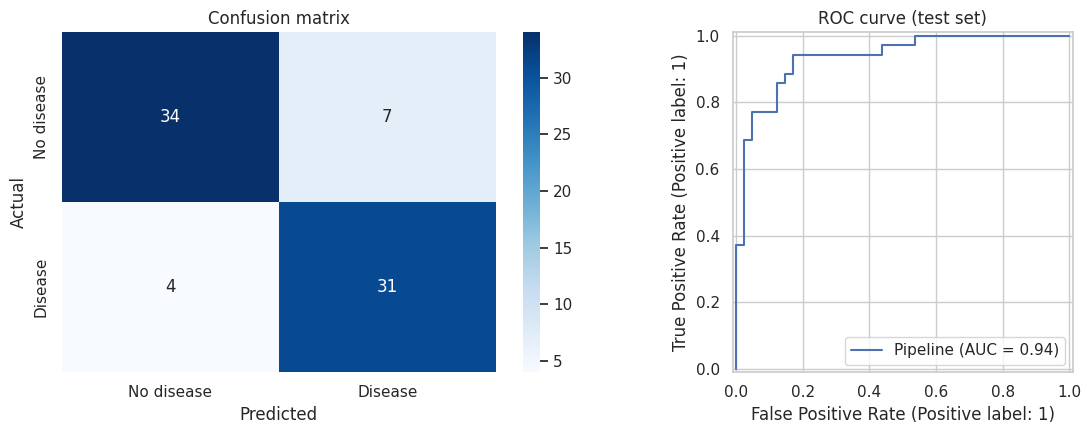

In [ ]:
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))
print("Test ROC AUC:", round(roc_auc_score(y_test, best_model.predict_proba(X_test)[:, 1]), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["No disease", "Disease"], yticklabels=["No disease", "Disease"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual"); axes[0].set_title("Confusion matrix")
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=axes[1])
axes[1].set_title("ROC curve (test set)")
plt.tight_layout(); plt.show()

## 7. Which features drive the predictions?
The Random Forest's impurity-based importances give a rough view of what the model relies on. These are not causal effects.

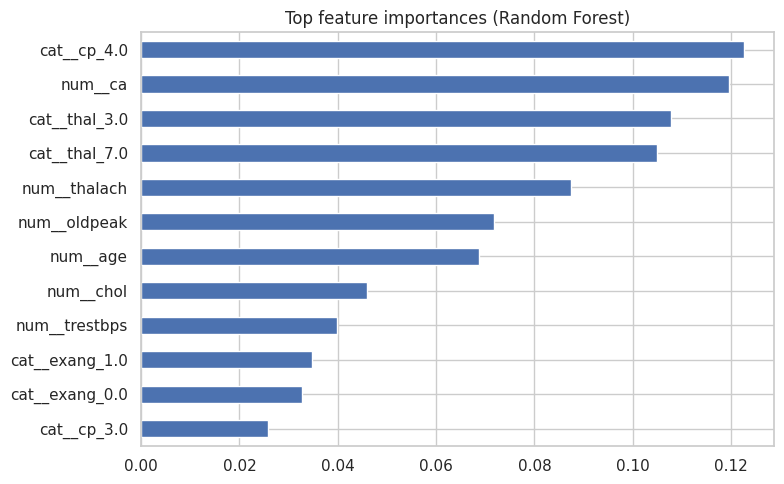

In [ ]:
feature_names = best_model.named_steps["pre"].get_feature_names_out()
importances = pd.Series(best_model.named_steps["clf"].feature_importances_, index=feature_names)
importances.sort_values().tail(12).plot.barh(figsize=(8, 5))
plt.title("Top feature importances (Random Forest)")
plt.tight_layout(); plt.show()

## 8. Ethical considerations
- **Potential bias:** The Cleveland data comes from one hospital system and is small (303 rows), and it is heavily skewed toward older male patients. Performance may not transfer to other populations.
- **Subgroup performance:** Before any use, we would report sensitivity and specificity separately by sex and age group. A model that looks accurate overall can miss disease in an under-represented group.
- **Transparency:** A Random Forest is hard to explain to a clinician. Logistic regression coefficients are easier to read, so we should show both before choosing a model.
- **Cost of errors:** A false negative (missed disease) is usually worse than a false positive (extra test). Threshold choice should reflect that, and clinicians should make the final decision.
- **Privacy:** Patient data must be de-identified and handled under the relevant data-protection rules. Do not upload identifiable records to a shared Colab session.

## 9. Team collaboration process
_Summarise roles, how work was split, how the GitHub repo was used, and what changed between iterations._